# Entrega final, parte 2: pronóstico diario de órdenes entrantes a 15 días

**BCD5105 · Modelado matemático · III Cuatrimestre 2026 · Lead University**

**Proyecto:** Pronóstico de las órdenes entrantes de LightForce Orthodontics a escala mensual y diaria

**Grupo:** 2

**Integrantes:** Daniel Vasquez Gonzalez, Santiago Villareal Arley, Maria José Gonzalez Quesada, Sharis Duarte Alvarado

Este notebook reproduce la parte 2 del proyecto: el pronóstico de las órdenes que entran cada día durante los 15 días siguientes, en hora de Costa Rica. Se compara un método clásico de descomposición (repartir el pronóstico mensual de la parte 1 entre los días con un perfil semanal y factores de feriado por país) con el modelo de fundación Chronos-2 con covariables, que es el segundo método principal, y con varios modelos de contraste (ETS, MSTL, SARIMAX, Prophet, TimesFM 2.5 y LightGBM). Todos se evalúan con la misma validación de 52 orígenes semanales. El pronóstico final es la combinación de los dos métodos principales, con un intervalo empírico cuya cobertura se verifica en la validación. La parte 1 (pronóstico mensual) está en `Notebook_1_Pronostico_Mensual.ipynb`.

Se ejecuta de principio a fin en un entorno limpio de Colab (Python 3). La validación tarda unos 20 minutos en CPU. Los datos se leen de `datos/ordenes_diarias.csv` si el archivo está junto al notebook, o del repositorio público en GitHub si no.

Contenido:
1. Configuración, versiones y semilla
2. Datos
3. Análisis exploratorio diario
4. Métodos
5. Validación de 52 orígenes
6. Resultados de la validación
7. Cobertura de los intervalos
8. Pronóstico del 12 al 26 de noviembre de 2026
9. Conclusiones

## 1. Configuración, versiones y semilla

In [1]:
%pip install -q statsforecast==2.1.1 prophet==1.5.0 chronos-forecasting==2.3.2 "timesfm[torch]==3.0.2" mlforecast==1.1.0 lightgbm==4.7.0 holidays==0.107

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, random, time, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import holidays, statsforecast, prophet, torch, timesfm, mlforecast, lightgbm as lgb
from importlib.metadata import version
from scipy.stats import wilcoxon
from statsmodels.tsa.seasonal import STL
from statsforecast import StatsForecast
from statsforecast.models import AutoETS, AutoARIMA, MSTL
from prophet import Prophet
from chronos import Chronos2Pipeline
from mlforecast import MLForecast
from mlforecast.lag_transforms import RollingMean

warnings.filterwarnings("ignore")
for nombre in ["cmdstanpy", "prophet"]:
    logging.getLogger(nombre).setLevel(logging.ERROR)
SEMILLA = 2026
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

print("pandas", pd.__version__, "| numpy", np.__version__, "| holidays", holidays.__version__, "| statsforecast", statsforecast.__version__)
print("prophet", prophet.__version__, "| mlforecast", mlforecast.__version__, "| lightgbm", lgb.__version__)
print("torch", torch.__version__, "| chronos-forecasting", version("chronos-forecasting"), "| timesfm", version("timesfm"))

# Estilo de las figuras: el mismo del notebook 1
C = dict(azul="#2a78d6", naranja="#eb6834", aqua="#1baf7a", tinta="#0b0b0b", tinta2="#52514e",
         tenue="#898781", rejilla="#e1e0d9", base="#c3c2b7", fondo="#fcfcfb")
plt.rcParams.update({
    "figure.facecolor": C["fondo"], "axes.facecolor": C["fondo"], "axes.edgecolor": C["base"],
    "axes.labelcolor": C["tinta2"], "xtick.color": C["tenue"], "ytick.color": C["tenue"],
    "text.color": C["tinta"], "axes.grid": True, "grid.color": C["rejilla"], "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "savefig.dpi": 200,
    "savefig.bbox": "tight", "figure.dpi": 110, "legend.frameon": False})
os.makedirs("figuras", exist_ok=True)
DIAS_SEM = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
FMT_DIA = mdates.DateFormatter("%d/%m")
nombres_mes = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
FMT_MES = FuncFormatter(lambda x, pos: "%s-%s" % (nombres_mes[mdates.num2date(x).month - 1], mdates.num2date(x).strftime("%y")))   # ej. ene-26

pandas 2.2.3 | numpy 2.4.6 | holidays 0.107 | statsforecast 2.1.1
prophet 1.5.0 | mlforecast 1.1.0 | lightgbm 4.7.0
torch 2.12.1+cpu | chronos-forecasting 2.3.2 | timesfm 3.0.2


## 2. Datos

Se usa el mismo archivo de la parte 1: `datos/ordenes_diarias.csv`, con las órdenes nuevas por día en hora de Costa Rica (UTC−6), el total, las de acero inoxidable y las de cada país de la cuenta (EE. UU. con Puerto Rico, Canadá, Australia y Nueva Zelanda). El origen de los datos y la consulta SQL están en la sección 2 del notebook 1.

A escala diaria el día se asigna en hora de Costa Rica porque es donde se atienden los casos. Esto mueve a Australia y Nueva Zelanda: su jornada laboral (8:00 a 18:00 locales, UTC+10/+11 y UTC+12/+13) cae entre la tarde del día anterior y la madrugada en Costa Rica. Por eso sus lunes llegan en domingo y sus feriados afectan, sobre todo, el día anterior en Costa Rica.

In [3]:
RUTA = "datos/ordenes_diarias.csv"
URL = "https://raw.githubusercontent.com/DannyV1992/curso_modelado/main/Tareas/Proyecto_integrador/Entrega_final/datos/ordenes_diarias.csv"
d = pd.read_csv(RUTA if os.path.exists(RUTA) else URL, parse_dates=["fecha"]).set_index("fecha")
P = ["us", "ca", "au", "nz"]
NOMBRE_PAIS = {"us": "EE. UU.", "ca": "Canadá", "au": "Australia", "nz": "N. Zelanda"}
assert d.index.is_unique and len(d) == (d.index[-1] - d.index[0]).days + 1, "debe haber un registro por día, sin huecos"
FIN = d.index[-1]                                                   # último día observado: 11 de noviembre de 2026
print("Días:", len(d), "|", d.index[0].date(), "a", FIN.date(), "| órdenes:", d.ordenes.sum())
print("Fuera de los cuatro países (solo cuentan en el total):", int((d.ordenes - d[P].sum(axis=1)).sum()))

Días: 1411 | 2023-01-01 a 2026-11-11 | órdenes: 213358
Fuera de los cuatro países (solo cuentan en el total): 1


## 3. Análisis exploratorio diario

### 3.1 Patrón semanal por país

In [4]:
ult = d[FIN - pd.Timedelta(weeks=52) + pd.Timedelta(days=1):]
perfil = ult[P].groupby(ult.index.dayofweek).mean()
print("Promedio de órdenes por día de la semana (hora CR), últimas 52 semanas:")
print(perfil.assign(total=ult.groupby(ult.index.dayofweek).ordenes.mean()).round(1).set_axis(DIAS_SEM).to_string())
stl7 = STL(d.ordenes.astype(float), period=7, robust=True).fit()
print("Fuerza de la estacionalidad semanal (STL, período 7): %.2f" % max(0, 1 - np.var(stl7.resid) / np.var(stl7.seasonal + stl7.resid)))
print("Australia y Nueva Zelanda aportan el %.0f %% de las órdenes del domingo en hora CR" %
      (100 * perfil.loc[6, ["au", "nz"]].sum() / perfil.loc[6].sum()))
print("Coeficiente de variación diario de lunes a viernes: %.2f" % (lambda x: x.std() / x.mean())(ult.ordenes[ult.index.dayofweek < 5]))

Promedio de órdenes por día de la semana (hora CR), últimas 52 semanas:
        us    ca    au   nz  total
lun  147.4  51.2  18.1  2.6  219.3
mar  164.8  59.8  19.0  1.9  245.5
mié  159.8  61.0  20.6  2.1  243.4
jue  154.0  61.6  17.5  3.3  236.4
vie   81.2  30.9   5.2  0.6  117.8
sáb   12.0   7.0   1.2  0.9   21.2
dom   13.1   7.9  12.9  1.9   35.8
Fuerza de la estacionalidad semanal (STL, período 7): 0.89
Australia y Nueva Zelanda aportan el 41 % de las órdenes del domingo en hora CR
Coeficiente de variación diario de lunes a viernes: 0.32


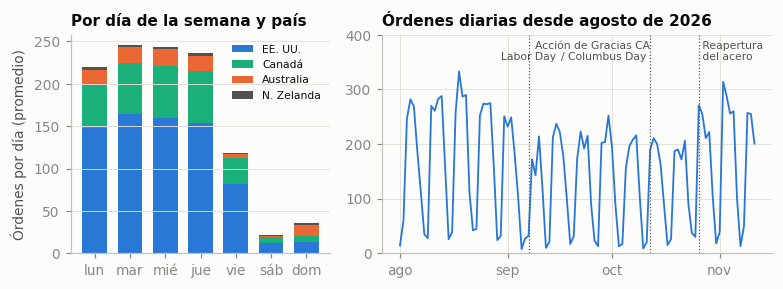

In [5]:
# Figura 4. Perfil semanal por país y serie diaria reciente
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 2.7), gridspec_kw={"width_ratios": [1, 1.5]})
abajo = np.zeros(7)
for p, col in zip(P, [C["azul"], C["aqua"], C["naranja"], C["tinta2"]]):
    a1.bar(range(7), perfil[p].values, bottom=abajo, color=col, label=NOMBRE_PAIS[p], width=0.7); abajo += perfil[p].values
a1.set_xticks(range(7)); a1.set_xticklabels(DIAS_SEM); a1.grid(axis="x", visible=False)
a1.set(ylabel="Órdenes por día (promedio)", title="Por día de la semana y país"); a1.legend(loc="upper right", fontsize=7)
tramo = d["2026-08-01":]
a2.plot(tramo.index, tramo.ordenes, color=C["azul"], lw=1.2)
for f, et, ha in [("2026-09-07", "Labor Day", "center"), ("2026-10-12", "Acción de Gracias CA\n/ Columbus Day ", "right"),
                  ("2026-10-26", " Reapertura\n del acero", "left")]:
    a2.axvline(pd.Timestamp(f), color=C["tinta2"], lw=0.8, ls=":")
    a2.annotate(et, xy=(pd.Timestamp(f), 350), fontsize=7, color=C["tinta2"], ha=ha, va="bottom")
a2.set(title="Órdenes diarias desde agosto de 2026", ylim=(0, 400))
a2.xaxis.set_major_locator(mdates.MonthLocator()); a2.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: nombres_mes[mdates.num2date(x).month - 1]))
fig.tight_layout(); fig.savefig("figuras/fig4_vista_diaria.png"); plt.show()

### 3.2 Feriados por país

Los feriados se toman de la librería `holidays` para cada país: EE. UU. (federales), Canadá (provincia de Ontario, la de más cuentas), Australia y Nueva Zelanda (nacionales). A EE. UU. se agregan Black Friday y la víspera de Thanksgiving; a EE. UU. y Canadá, los días entre Navidad y Año Nuevo y el 2 de enero, en los que las clínicas trabajan poco. Para Australia y Nueva Zelanda la fecha del feriado se desplaza un día hacia atrás, que es cuando cae su jornada en hora de Costa Rica. La comparación siguiente lo confirma: en un feriado de esos países, las órdenes del día anterior en Costa Rica caen más que las del mismo día.

In [6]:
ANIOS = range(2023, 2028)
CALENDARIOS = {"us": (holidays.US(years=ANIOS), 0), "ca": (holidays.CA(subdiv="ON", years=ANIOS), 0),
               "au": (holidays.AU(years=ANIOS), -1), "nz": (holidays.NZ(years=ANIOS), -1)}

def base_semanas(serie, t):
    """Mediana del mismo día de la semana en las 4 semanas anteriores (referencia de un día normal)."""
    prev = [t - pd.Timedelta(weeks=k) for k in range(1, 5)]
    return serie.loc[[x for x in prev if x in serie.index]].median()

for p in ["au", "nz"]:
    cal, _ = CALENDARIOS[p]
    r = {0: [], -1: []}
    for f in cal:
        f = pd.Timestamp(f)
        if f.dayofweek >= 5 or not (d.index[0] + pd.Timedelta(weeks=4) <= f <= FIN):
            continue
        for desf in r:
            t = f + pd.Timedelta(days=desf)
            b = base_semanas(d[p], t)
            if b > 0:
                r[desf].append(d.loc[t, p] / b)
    print("%-10s %d feriados entre semana | órdenes / día normal: mismo día en CR %.2f, día anterior en CR %.2f" %
          (NOMBRE_PAIS[p], len(r[0]), np.median(r[0]), np.median(r[-1])))

Australia  22 feriados entre semana | órdenes / día normal: mismo día en CR 0.59, día anterior en CR 0.24
N. Zelanda 33 feriados entre semana | órdenes / día normal: mismo día en CR 0.20, día anterior en CR 0.00


In [7]:
def eventos():
    """Calendario de eventos por país, en la fecha de Costa Rica."""
    filas = []
    for p, (cal, desf) in CALENDARIOS.items():
        for f, n in cal.items():
            filas.append((p, pd.Timestamp(f) + pd.Timedelta(days=desf), n.replace(" (observed)", "")))
        if p in ("us", "ca"):
            for y in ANIOS:
                for dd in [24, 26, 27, 28, 29, 30, 31]:
                    if not (p == "ca" and dd == 26):                 # el 26 ya es Boxing Day en Canadá
                        filas.append((p, pd.Timestamp(y, 12, dd), "Dic %d" % dd))
                filas.append((p, pd.Timestamp(y, 1, 2), "Ene 2"))
        if p == "us":
            for f, n in cal.items():
                if n == "Thanksgiving Day":
                    filas.append((p, pd.Timestamp(f) + pd.Timedelta(days=1), "Black Friday"))
                    filas.append((p, pd.Timestamp(f) - pd.Timedelta(days=1), "Víspera de Thanksgiving"))
    return pd.DataFrame(filas, columns=["pais", "fecha", "evento"]).drop_duplicates(["pais", "fecha"])

EV = eventos()
ES_EV = {p: set(EV[EV.pais == p].fecha) for p in P}
EV_P = {p: EV[EV.pais == p].set_index("fecha").evento for p in P}
print("Eventos por país, 2023 a 2027:", EV.groupby("pais").size().to_dict())

Eventos por país, 2023 a 2027: {'au': 35, 'ca': 80, 'nz': 63, 'us': 109}


El efecto de cada evento se estima con su historia: el **factor de feriado** $f_p(e)$ es la mediana, entre las ocurrencias del evento $e$ hasta el origen, del cociente entre las órdenes del país $p$ ese día y la mediana del mismo día de la semana en las 4 semanas anteriores (sin feriados). Un factor de 0.2 significa que ese día llega el 20 % de lo normal. Se acota en 1.5 para que un evento con una sola ocurrencia atípica no domine.

In [8]:
_cache_fac = {}
def factores(T):
    """Factor de feriado por (país, evento), con las ocurrencias hasta el origen T."""
    if T not in _cache_fac:
        ev = EV[(EV.fecha <= T) & (EV.fecha >= d.index[0] + pd.Timedelta(weeks=4))].copy()
        def cociente(p, t):
            prev = [t - pd.Timedelta(weeks=k) for k in range(1, 5)]
            b = d.loc[[x for x in prev if x in d.index and x not in ES_EV[p]], p].median()
            return d.loc[t, p] / b if b > 0 else np.nan
        ev["r"] = [cociente(p, t) for p, t in zip(ev.pais, ev.fecha)]
        _cache_fac[T] = ev.groupby(["pais", "evento"]).r.agg(["median", "count"]).assign(median=lambda x: x["median"].clip(upper=1.5))
    return _cache_fac[T]

fac_fin = factores(FIN)
print("Factores de feriado con los datos hasta el %s (eventos con al menos 2 ocurrencias, los de mayor efecto):" % FIN.date())
for p in P:
    f = fac_fin.loc[p]
    f = f[f["count"] >= 2].sort_values("median").head(6)
    print("\n" + NOMBRE_PAIS[p] + ":\n" + f.rename(columns={"median": "factor", "count": "ocurrencias"}).round(2).to_string())

Factores de feriado con los datos hasta el 2026-11-11 (eventos con al menos 2 ocurrencias, los de mayor efecto):



EE. UU.:
                  factor  ocurrencias
evento                               
Christmas Day       0.02            3
New Year's Day      0.07            3
Thanksgiving Day    0.08            3
Labor Day           0.12            4
Independence Day    0.17            5
Black Friday        0.19            3

Canadá:
                factor  ocurrencias
evento                             
New Year's Day    0.00            3
Christmas Day     0.02            3
Victoria Day      0.08            4
Dic 31            0.09            3
Labour Day        0.11            4
Boxing Day        0.14            3

Australia:
                factor  ocurrencias
evento                             
Christmas Day     0.00            3
New Year's Day    0.00            3
Easter Monday     0.04            4
Boxing Day        0.06            3
Australia Day     0.44            3
Good Friday       0.51            4

N. Zelanda:
                          factor  ocurrencias
evento                       

### 3.3 El acero a escala diaria

La proporción diaria de acero muestra las dos decisiones de capacidad de 2026: el cierre a inicios de septiembre y la reapertura del 26 de octubre.

In [9]:
sem = d["2026-01-01":].resample("W-SUN").sum()
print((sem.acero / sem.ordenes).round(3).rename("proporción de acero por semana").to_string())

fecha
2026-01-04    0.000
2026-01-11    0.003
2026-01-18    0.004
2026-01-25    0.005
2026-02-01    0.006
2026-02-08    0.013
2026-02-15    0.012
2026-02-22    0.017
2026-03-01    0.012
2026-03-08    0.025
2026-03-15    0.023
2026-03-22    0.022
2026-03-29    0.029
2026-04-05    0.030
2026-04-12    0.039
2026-04-19    0.064
2026-04-26    0.086
2026-05-03    0.107
2026-05-10    0.147
2026-05-17    0.207
2026-05-24    0.190
2026-05-31    0.229
2026-06-07    0.251
2026-06-14    0.254
2026-06-21    0.262
2026-06-28    0.299
2026-07-05    0.307
2026-07-12    0.323
2026-07-19    0.294
2026-07-26    0.333
2026-08-02    0.338
2026-08-09    0.356
2026-08-16    0.302
2026-08-23    0.306
2026-08-30    0.306
2026-09-06    0.141
2026-09-13    0.023
2026-09-20    0.017
2026-09-27    0.008
2026-10-04    0.006
2026-10-11    0.008
2026-10-18    0.007
2026-10-25    0.009
2026-11-01    0.197
2026-11-08    0.338
2026-11-15    0.208
Freq: W-SUN


## 4. Métodos

El horizonte es de $H = 15$ días a partir del día siguiente al origen $T$. Hay cuatro grupos de métodos:

| Grupo | Método | Idea |
|---|---|---|
| Referencia | SN7 | Ingenuo estacional semanal: $\hat y_{T+h} = y_{T+h-7k}$, con $k = \lceil h/7 \rceil$ |
| **Método 1: descomposición clásica** | A1, reparto del pronóstico mensual | El SNAIVE_dh de la parte 1 da el total del mes y se reparte entre sus días con el perfil semanal de cada país y los factores de feriado |
| | A2 | Igual que A1, pero en el mes en curso reparte solo lo que falta (pronóstico del mes menos lo ya observado) |
| | P4, P8, P26 | Solo el perfil semanal por país de las últimas 4, 8 o 26 semanas, con los factores de feriado, sin pronóstico mensual |
| **Método 2: modelo de fundación (principal)** | Chronos-2 con covariables | Chronos-2 recibe como covariables conocidas la pérdida esperada por feriado de cada país, $1 - f_p(t)$, y la proporción de acero |
| Contrastes | Chronos-2 univariado, TimesFM 2.5 | Modelos de fundación sin covariables |
| | AutoETS (m = 7), MSTL (7 y 365) | Suavizamiento exponencial y descomposición con dos estacionalidades |
| | SARIMAX (m = 7) | SARIMA semanal con las mismas covariables de Chronos-2 como regresores |
| | Prophet | Tendencia, estacionalidad semanal y anual multiplicativas, un efecto por feriado y país, acero como regresor |
| | LightGBM | Árboles con gradiente (mlforecast), recursivo, con rezagos de 1 a 28 días, medias móviles, día de la semana, mes y las covariables |
| **Final** | C = (A1 + Chronos-2 con covariables) / 2 | Combinación de los dos métodos principales |

**Método 1 (A1).** El nivel esperado del país $p$ en el día $t$ es $n_{p,t} = s_p(w_t)\, f_p(t)$, donde $s_p(w)$ es el promedio del país en el día de la semana $w$ en las últimas 26 semanas (sin feriados) y $f_p(t)$ es el factor de feriado del evento de ese día (1 si no hay). Con $\hat Y_M$ el pronóstico SNAIVE_dh del mes $M$, cada día recibe

$$\hat y_t = \hat Y_M \, \frac{\sum_p n_{p,t}}{\sum_{u \in M} \sum_p n_{p,u}}.$$

Es un pronóstico jerárquico *top-down* con proporciones pronosticadas (Hyndman y Athanasopoulos, 2021, cap. 11). P4, P8 y P26 usan directamente $\hat y_t = \sum_p n_{p,t}$, con el perfil de 4, 8 o 26 semanas.

**Método 2 (Chronos-2).** Se usa sin ajuste, con el contexto de toda la historia diaria. Las covariables son conocidas en el horizonte: los feriados por calendario y, para la proporción de acero, la **persistencia** del promedio de los últimos 14 días (la misma idea de la parte 1). Como cota se corre también con la proporción diaria realizada, que representa conocer el plan de capacidad.

**Por qué se combinan.** A1 sabe de feriados y del total del mes, pero su perfil es rígido. Chronos-2 sigue mejor el nivel reciente, pero en feriados solo tiene la covariable. Promediar pronósticos con errores distintos suele reducir el error (Hyndman y Athanasopoulos, 2021, sec. 13.4).

In [10]:
H = 15
mensual = d.ordenes.resample("MS").sum()

def dias_habiles_mes(m):
    return np.busday_count(m.date(), (m + pd.offsets.MonthBegin(1)).date())

def snaive_dh(M):
    """Pronóstico mensual de la parte 1: el mismo mes del año anterior, ajustado por días hábiles."""
    M12 = M - pd.DateOffset(years=1)
    return dias_habiles_mes(M) * mensual[M12] / dias_habiles_mes(M12)

def nivel(T, dias, semanas=26):
    """n_{p,t} = s_p(w_t) f_p(t): perfil semanal reciente de cada país por el factor de feriado del día."""
    hist = d[T - pd.Timedelta(weeks=semanas) + pd.Timedelta(days=1):T]
    fac = factores(T)["median"]
    out = pd.DataFrame(index=dias)
    for p in P:
        h = hist[p][~hist.index.isin(ES_EV[p])]
        s = h.groupby(h.index.dayofweek).mean()
        f = [fac.get((p, EV_P[p][t]), 1.0) if t in EV_P[p].index else 1.0 for t in dias]
        out[p] = s.reindex(dias.dayofweek).values * np.array(f)
    return out

def fc_reparto(T, dias, descontar_observado=False):
    """A1 (y A2 si descontar_observado): reparte el pronóstico mensual entre los días del mes con n_{p,t}."""
    res = pd.Series(np.nan, index=dias)
    for M in sorted(set(dias.to_period("M"))):
        Mi = M.to_timestamp()
        todos = pd.date_range(Mi, Mi + pd.offsets.MonthEnd(0))
        n = nivel(T, todos).sum(axis=1)
        Y = snaive_dh(Mi)
        sel = res.index[res.index.isin(todos)]
        if descontar_observado and Mi <= T:
            resto = n[n.index > T]
            res[sel] = max(0, Y - d.ordenes[Mi:T].sum()) * (resto / resto.sum()).reindex(sel).values
        else:
            res[sel] = Y * (n / n.sum()).reindex(sel).values
    return res

def fc_perfil(T, dias, semanas):
    return nivel(T, dias, semanas).sum(axis=1)

def fc_sn7(T, dias):
    return np.array([d.ordenes[t - pd.Timedelta(weeks=int(np.ceil((t - T).days / 7)))] for t in dias])

In [11]:
chronos2 = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map="cpu")
tfm = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch")
tfm.compile(timesfm.ForecastConfig(max_context=1024, max_horizon=64, normalize_inputs=True, use_continuous_quantile_head=True,
                                   force_flip_invariance=True, infer_is_positive=True, fix_quantile_crossing=True))
NIV = ["-lo-80", "-hi-80", "-lo-95", "-hi-95"]
QS = {"-lo-80": "0.1", "-hi-80": "0.9", "-lo-95": "0.025", "-hi-95": "0.975"}

def covariables(T, dias):
    """Pérdida esperada por feriado de cada país, 1 - f_p(t), con los factores estimados hasta T."""
    fac = factores(T)["median"]
    X = pd.DataFrame(index=dias)
    for p in P:
        X["fer_" + p] = [1 - fac.get((p, EV_P[p][t]), 1.0) if t in EV_P[p].index else 0.0 for t in dias]
    return X

def acero_persistencia(T, n):
    u = d[T - pd.Timedelta(days=13):T]
    return np.full(n, u.acero.sum() / u.ordenes.sum())

def modelos_directos(T, dias):
    """Métodos que modelan la serie diaria total: Chronos-2, TimesFM, ETS, MSTL, SARIMAX, Prophet y LightGBM."""
    tr = d[:T]
    out = pd.DataFrame(index=dias)
    df = pd.DataFrame({"unique_id": "o", "ds": tr.index, "y": tr.ordenes.values.astype(float)})
    Xh = covariables(T, tr.index); Xh["acero"] = (tr.acero / tr.ordenes.clip(lower=1)).values
    Xf = covariables(T, dias); Xf["acero"] = acero_persistencia(T, len(dias))
    dfx = pd.concat([df, Xh.reset_index(drop=True)], axis=1)
    Xfdf = pd.concat([pd.DataFrame({"unique_id": "o", "ds": dias}), Xf.reset_index(drop=True)], axis=1)

    f = StatsForecast(models=[AutoETS(season_length=7, alias="ETS"), MSTL(season_length=[7, 365], alias="MSTL")],
                      freq="D").forecast(df=df, h=H, level=[80, 95])
    for m in ["ETS", "MSTL"]:
        for s_ in [""] + NIV:
            out[m + s_] = f[m + s_].values
    f = StatsForecast(models=[AutoARIMA(season_length=7, alias="SARIMAX")], freq="D").forecast(df=dfx, h=H, X_df=Xfdf, level=[80, 95])
    for s_ in [""] + NIV:
        out["SARIMAX" + s_] = f["SARIMAX" + s_].values

    hol = EV[EV.fecha <= dias[-1]].assign(holiday=lambda x: x.pais + ": " + x.evento).rename(columns={"fecha": "ds"})[["holiday", "ds"]]
    m = Prophet(holidays=hol, weekly_seasonality=True, yearly_seasonality=True, daily_seasonality=False,
                seasonality_mode="multiplicative", uncertainty_samples=300)
    m.add_regressor("acero", mode="multiplicative")
    m.fit(pd.DataFrame({"ds": tr.index, "y": tr.ordenes.values, "acero": Xh.acero.values}))
    fut = pd.DataFrame({"ds": dias, "acero": Xf.acero.values})
    sim = m.predictive_samples(fut)["yhat"]
    out["Prophet"] = m.predict(fut)["yhat"].values
    for s_, q in zip(NIV, [0.1, 0.9, 0.025, 0.975]):
        out["Prophet" + s_] = np.quantile(sim, q, axis=1)

    ctx = pd.DataFrame({"id": "o", "timestamp": tr.index, "target": tr.ordenes.values.astype(float)})
    ctx_cov = pd.concat([ctx, Xh.reset_index(drop=True)], axis=1)
    fut_cov = pd.concat([pd.DataFrame({"id": "o", "timestamp": dias}), Xf.reset_index(drop=True)], axis=1)
    fut_plan = fut_cov.assign(acero=(d.acero / d.ordenes.clip(lower=1)).reindex(dias).values)   # cota: proporción realizada
    for nom, c_, f_ in [("Chronos2", ctx, None), ("Chronos2_cov", ctx_cov, fut_cov), ("Chronos2_cov_plan", ctx_cov, fut_plan)]:
        if nom == "Chronos2_cov_plan" and f_.acero.isna().any():
            continue                                                   # en el pronóstico final no hay proporción realizada
        o = chronos2.predict_df(c_, future_df=f_, prediction_length=H, quantile_levels=[0.025, 0.1, 0.5, 0.9, 0.975],
                                id_column="id", timestamp_column="timestamp", target="target")
        out[nom] = o["0.5"].values
        for s_ in NIV:
            out[nom + s_] = o[QS[s_]].values

    punto, cuant = tfm.forecast(horizon=H, inputs=[tr.ordenes.values.astype(float)[-1024:]])
    out["TimesFM"], out["TimesFM-lo-80"], out["TimesFM-hi-80"] = punto[0], cuant[0][:, 1], cuant[0][:, 9]   # deciles 1 y 9

    mlf = MLForecast(models={"LightGBM": lgb.LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=10,
                                                         subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEMILLA, verbose=-1)},
                     freq="D", lags=[1, 7, 14, 21, 28], lag_transforms={7: [RollingMean(window_size=28)], 1: [RollingMean(window_size=7)]},
                     date_features=["dayofweek", "month"])
    mlf.fit(dfx, static_features=[])
    out["LightGBM"] = mlf.predict(h=H, X_df=Xfdf)["LightGBM"].values
    return out

def pronosticar(T):
    dias = pd.date_range(T + pd.Timedelta(days=1), periods=H)
    r = modelos_directos(T, dias)
    r["SN7"] = fc_sn7(T, dias)
    r["A1"] = fc_reparto(T, dias)
    r["A2"] = fc_reparto(T, dias, descontar_observado=True)
    for s in [4, 8, 26]:
        r["P%d" % s] = fc_perfil(T, dias, s)
    puntos = [c for c in r.columns if "-" not in c]
    r[puntos] = r[puntos].clip(lower=0)                               # restricción: los conteos no son negativos
    r["C"] = (r.A1 + r.Chronos2_cov) / 2
    return r

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

## 5. Validación de 52 orígenes

Los orígenes son los 52 domingos del 2 de noviembre de 2025 al 25 de octubre de 2026. Cada uno pronostica de lunes a lunes de la semana siguiente (15 días), y en cada origen todo (perfiles, factores de feriado, modelos) se estima solo con los días hasta el origen. Los 52 orígenes cubren un año completo, con Thanksgiving, Navidad, Año Nuevo, Semana Santa, los feriados de Australia y Nueva Zelanda y el auge y la pausa del acero.

El error de cada origen se mide con el **MASE diario**: el error absoluto medio de los 15 días dividido entre el error absoluto medio del ingenuo semanal ($y_t - y_{t-7}$) dentro del entrenamiento. Además se reporta el error porcentual del total de los 15 días, que es lo que importa para planificar la capacidad de las dos semanas.

In [12]:
ORIGENES = pd.date_range("2025-11-02", "2026-10-25", freq="7D")
assert len(ORIGENES) == 52 and (ORIGENES.dayofweek == 6).all()
t0 = time.time()
partes = []
for i, T in enumerate(ORIGENES):
    r = pronosticar(T)
    r["T"], r["y"], r["h"] = T, d.ordenes.reindex(r.index).values, np.arange(1, H + 1)
    tr = d.ordenes[:T].values.astype(float)
    r["esc"] = np.mean(np.abs(tr[7:] - tr[:-7]))
    partes.append(r)
    if (i + 1) % 13 == 0:
        print("%d de 52 orígenes, %.1f minutos" % (i + 1, (time.time() - t0) / 60))
V = pd.concat(partes).rename_axis("fecha").reset_index()
print("Pronósticos evaluados por método:", len(V))

13 de 52 orígenes, 3.7 minutos


26 de 52 orígenes, 7.1 minutos


39 de 52 orígenes, 9.1 minutos


52 de 52 orígenes, 11.7 minutos
Pronósticos evaluados por método: 780


## 6. Resultados de la validación

In [13]:
METODOS = ["C", "A1", "A2", "P4", "P8", "P26", "Chronos2_cov", "Chronos2", "TimesFM", "ETS", "MSTL", "SARIMAX", "Prophet", "LightGBM", "SN7"]
ev_us_ca = set(EV[EV.pais.isin(["us", "ca"])].fecha)
V["feriado"] = V.fecha.isin(ev_us_ca)                                # días con evento en EE. UU. o Canadá (el 93 % de las órdenes)
ea = lambda m: (V.y - V[m]).abs() / V.esc
mase_o = pd.DataFrame({m: ea(m).groupby(V["T"]).mean() for m in METODOS + ["Chronos2_cov_plan"]})
g = V.groupby("T")
err_total = pd.DataFrame({m: 100 * (g[m].sum() - g.y.sum()) / g.y.sum() for m in METODOS + ["Chronos2_cov_plan"]})
tabla = pd.DataFrame({m: {"MASE": mase_o[m].mean(), "MASE mediana": mase_o[m].median(),
                          "MASE días 1-7": ea(m)[V.h <= 7].mean(), "MASE días 8-15": ea(m)[V.h > 7].mean(),
                          "MASE en feriados": ea(m)[V.feriado].mean(),
                          "gana a SN7": (mase_o[m] < mase_o.SN7).sum() if m != "SN7" else np.nan,
                          "p vs SN7": wilcoxon(mase_o[m], mase_o.SN7).pvalue if m != "SN7" else np.nan,
                          "error % total 15 días": err_total[m].abs().mean(),
                          "sesgo (órdenes/día)": (V[m] - V.y).mean()} for m in METODOS + ["Chronos2_cov_plan"]}).T.astype(float).sort_values("MASE")
print("Días evaluados: %d (52 orígenes x 15), de ellos %d con evento en EE. UU. o Canadá" % (len(V), V.feriado.sum()))
print(tabla.round(3).to_string())

Días evaluados: 780 (52 orígenes x 15), de ellos 57 con evento en EE. UU. o Canadá
                    MASE  MASE mediana  MASE días 1-7  MASE días 8-15  MASE en feriados  gana a SN7  p vs SN7  error % total 15 días  sesgo (órdenes/día)
Chronos2_cov_plan  0.663         0.620          0.635           0.688             1.060        49.0     0.000                  5.116                0.328
C                  0.680         0.638          0.641           0.714             0.865        46.0     0.000                  6.043               -2.704
Chronos2_cov       0.701         0.658          0.654           0.741             1.098        48.0     0.000                  6.062                0.383
LightGBM           0.716         0.660          0.683           0.745             0.784        45.0     0.000                  7.190                2.623
A1                 0.737         0.683          0.714           0.757             0.732        39.0     0.000                  7.723               

In [14]:
print("Pruebas de Wilcoxon pareadas sobre el MASE de los 52 orígenes:")
for a, b in [("C", "Chronos2_cov"), ("C", "A1"), ("Chronos2_cov", "A1"), ("Chronos2_cov", "Chronos2"),
             ("Chronos2_cov", "LightGBM"), ("A1", "P26"), ("A1", "A2"), ("Chronos2_cov_plan", "Chronos2_cov")]:
    print("  %-17s contra %-12s gana en %2d de 52 | MASE %.3f contra %.3f | p = %.3f" %
          (a, b, (mase_o[a] < mase_o[b]).sum(), mase_o[a].mean(), mase_o[b].mean(), wilcoxon(mase_o[a], mase_o[b]).pvalue))

# Por qué falla A2: si el pronóstico mensual se queda corto, lo que resta del mes se reparte entre pocos días y se acerca a cero
peor = mase_o.A2.idxmax()
print("\nOrigen con el peor A2: %s | MASE A2 = %.2f, A1 = %.2f" % (peor.date(), mase_o.A2[peor], mase_o.A1[peor]))
print(V[V["T"] == peor][["fecha", "y", "A1", "A2"]].round(0).head(8).to_string(index=False))

Pruebas de Wilcoxon pareadas sobre el MASE de los 52 orígenes:
  C                 contra Chronos2_cov gana en 26 de 52 | MASE 0.680 contra 0.701 | p = 0.339
  C                 contra A1           gana en 34 de 52 | MASE 0.680 contra 0.737 | p = 0.006
  Chronos2_cov      contra A1           gana en 31 de 52 | MASE 0.701 contra 0.737 | p = 0.212
  Chronos2_cov      contra Chronos2     gana en 36 de 52 | MASE 0.701 contra 0.791 | p = 0.000
  Chronos2_cov      contra LightGBM     gana en 30 de 52 | MASE 0.701 contra 0.716 | p = 0.299
  A1                contra P26          gana en 28 de 52 | MASE 0.737 contra 0.780 | p = 0.372
  A1                contra A2           gana en 36 de 52 | MASE 0.737 contra 0.971 | p = 0.000
  Chronos2_cov_plan contra Chronos2_cov gana en 36 de 52 | MASE 0.663 contra 0.701 | p = 0.000

Origen con el peor A2: 2026-06-21 | MASE A2 = 2.09, A1 = 1.33
     fecha   y    A1    A2
2026-06-22 290 222.0 179.0
2026-06-23 369 250.0 200.0
2026-06-24 340 269.0 216.0
2026-0

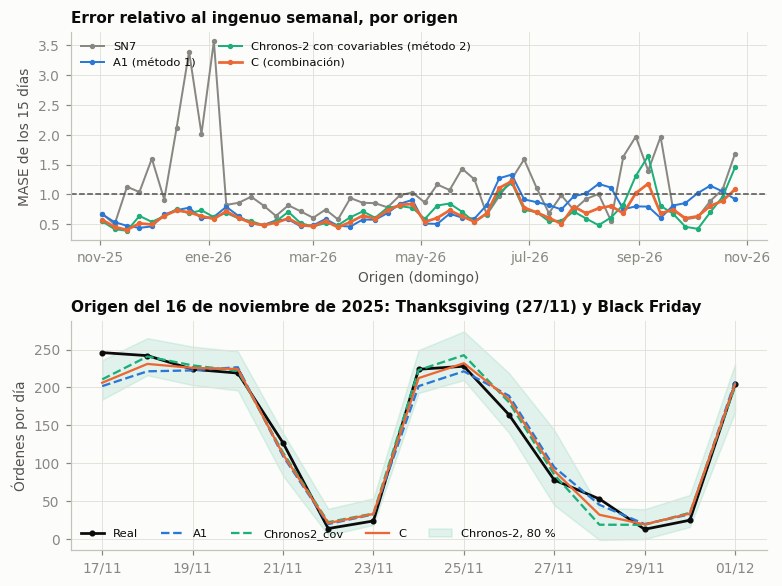

In [15]:
# Figura 9. MASE por origen y un ejemplo con Thanksgiving
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7.2, 5.4), gridspec_kw={"height_ratios": [1, 1.1]})
for m, col, et in [("SN7", C["tenue"], "SN7"), ("A1", C["azul"], "A1 (método 1)"),
                   ("Chronos2_cov", C["aqua"], "Chronos-2 con covariables (método 2)"), ("C", C["naranja"], "C (combinación)")]:
    a1.plot(mase_o.index, mase_o[m], color=col, lw=1.8 if m == "C" else 1.3, marker="o", ms=2.5, label=et)
a1.axhline(1, color=C["tinta2"], lw=1, ls="--")
a1.set(ylabel="MASE de los 15 días", title="Error relativo al ingenuo semanal, por origen", xlabel="Origen (domingo)")
a1.legend(loc="upper left", ncol=2, fontsize=7.5)
a1.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); a1.xaxis.set_major_formatter(FMT_MES)

T_ej = pd.Timestamp("2025-11-16")
ej = V[V["T"] == T_ej].set_index("fecha")
a2.plot(ej.index, ej.y, color=C["tinta"], lw=1.8, marker="o", ms=3, label="Real")
for m, col, ls in [("A1", C["azul"], "--"), ("Chronos2_cov", C["aqua"], "--"), ("C", C["naranja"], "-")]:
    a2.plot(ej.index, ej[m], color=col, lw=1.5, ls=ls, label=m)
a2.fill_between(ej.index, ej["Chronos2_cov-lo-80"], ej["Chronos2_cov-hi-80"], color=C["aqua"], alpha=0.12, label="Chronos-2, 80 %")
a2.set(ylabel="Órdenes por día", title="Origen del 16 de noviembre de 2025: Thanksgiving (27/11) y Black Friday")
a2.legend(loc="lower left", ncol=5, fontsize=7.5); a2.xaxis.set_major_formatter(FMT_DIA)
fig.tight_layout(); fig.savefig("figuras/fig9_validacion_diaria.png"); plt.show()

## 7. Cobertura de los intervalos

Se mide la cobertura de los intervalos del 80 % y 95 % en los 780 días de la validación. Para los modelos con intervalos propios (ETS, MSTL, SARIMAX, Prophet, Chronos-2 y TimesFM) se usan esos. A1 y la combinación C no tienen un intervalo propio, así que se les construye un **intervalo empírico**: en cada origen se toman los cocientes real/pronóstico de los días ya observados de los orígenes anteriores, por bloque de horizonte (días 1 a 7 y 8 a 15), y se usan sus cuantiles 10 y 90 (o 2.5 y 97.5). Se exige un mínimo de 4 orígenes previos, así que se evalúa en los últimos 48 orígenes. Con eso, el intervalo nunca usa información posterior al origen.

In [16]:
V["bloque"] = np.where(V.h <= 7, 1, 2)
def empirico(m, nivel, minimo=4):
    a = (1 - nivel / 100) / 2
    lo, hi = pd.Series(np.nan, index=V.index), pd.Series(np.nan, index=V.index)
    for T, gT in V.groupby("T"):
        prev = V[V.fecha <= T]
        if prev["T"].nunique() < minimo:
            continue
        for b, gb in gT.groupby("bloque"):
            r = (prev.y / prev[m].clip(lower=1))[prev.bloque == b]
            lo[gb.index], hi[gb.index] = gb[m] * r.quantile(a), gb[m] * r.quantile(1 - a)
    return lo, hi

for m in ["C", "A1", "Chronos2_cov"]:
    for nivel_ in [80, 95]:
        V["%s_emp-lo-%d" % (m, nivel_)], V["%s_emp-hi-%d" % (m, nivel_)] = empirico(m, nivel_)

evaluable = V["T"] >= ORIGENES[3]
filas = []
for m, et in [("C_emp", "C, empírico"), ("A1_emp", "A1, empírico"), ("Chronos2_cov_emp", "Chronos-2 cov., empírico"),
              ("Chronos2_cov", "Chronos-2 cov., cuantiles"), ("Chronos2", "Chronos-2, cuantiles"), ("TimesFM", "TimesFM 2.5"),
              ("ETS", "AutoETS"), ("MSTL", "MSTL"), ("SARIMAX", "SARIMAX"), ("Prophet", "Prophet")]:
    fila = {"intervalo": et}
    for nivel_ in [80, 95]:
        lo_c, hi_c = "%s-lo-%d" % (m, nivel_), "%s-hi-%d" % (m, nivel_)
        if lo_c not in V:
            continue
        dentro = (V.y >= V[lo_c]) & (V.y <= V[hi_c])
        fila["cob %d" % nivel_] = dentro[evaluable].mean()
        fila["cob %d feriados" % nivel_] = dentro[evaluable & V.feriado].mean()
        fila["ancho %d (órdenes)" % nivel_] = (V[hi_c] - V[lo_c])[evaluable].mean()
    filas.append(fila)
cob = pd.DataFrame(filas).set_index("intervalo")
print("Cobertura en los %d días de los orígenes 4 a 52 (proporción de días con el valor real dentro del intervalo):" % evaluable.sum())
print(cob.astype(float).round(2).to_string())

Cobertura en los 735 días de los orígenes 4 a 52 (proporción de días con el valor real dentro del intervalo):
                           cob 80  cob 80 feriados  ancho 80 (órdenes)  cob 95  cob 95 feriados  ancho 95 (órdenes)
intervalo                                                                                                          
C, empírico                  0.77             0.40               84.07    0.93             0.60              164.28
A1, empírico                 0.75             0.46               78.71    0.92             0.67              163.48
Chronos-2 cov., empírico     0.75             0.37               86.96    0.91             0.56              200.81
Chronos-2 cov., cuantiles    0.73             0.50               54.45    0.94             0.87              101.63
Chronos-2, cuantiles         0.73             0.69               58.70    0.94             0.87              111.73
TimesFM 2.5                  0.76             0.62               61.68     NaN

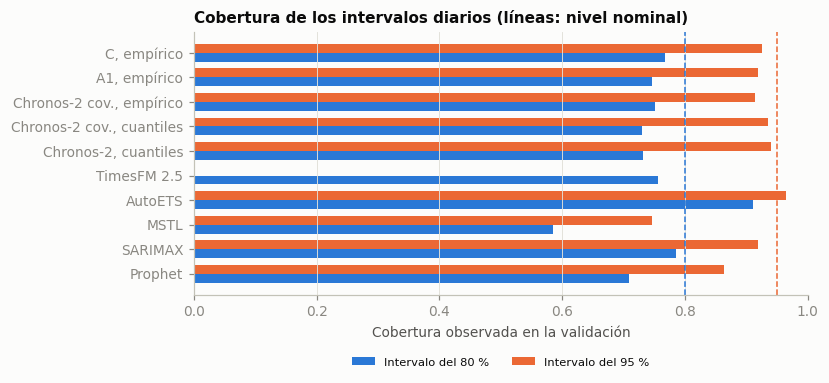

In [17]:
# Figura 10. Cobertura observada contra la nominal
fig, ax = plt.subplots(figsize=(7.2, 3.1))
yy = np.arange(len(cob))
ax.barh(yy + 0.18, cob["cob 80"], height=0.36, color=C["azul"], label="Intervalo del 80 %")
ax.barh(yy - 0.18, cob["cob 95"], height=0.36, color=C["naranja"], label="Intervalo del 95 %")
for v, col in [(0.80, C["azul"]), (0.95, C["naranja"])]:
    ax.axvline(v, color=col, lw=1, ls="--")
ax.set_yticks(yy); ax.set_yticklabels(cob.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set(xlabel="Cobertura observada en la validación", xlim=(0, 1), title="Cobertura de los intervalos diarios (líneas: nivel nominal)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=7.5)
fig.savefig("figuras/fig10_cobertura_diaria.png"); plt.show()

## 8. Pronóstico del 12 al 26 de noviembre de 2026

El origen es el último día observado, el miércoles 11 de noviembre de 2026. El horizonte termina con la víspera de Thanksgiving (25 de noviembre) y Thanksgiving (26 de noviembre) en EE. UU.; no hay feriados de Canadá, Australia ni Nueva Zelanda en esos días. El pronóstico mensual que A1 reparte es el SNAIVE_dh de noviembre de la parte 1 (4,396 órdenes). La proporción de acero para Chronos-2 es la de los últimos 14 días, que ya están después de la reapertura. El intervalo de C es el empírico, con los cocientes de los 52 orígenes de la validación.

In [18]:
fp = pronosticar(FIN)
dias_f = fp.index
fp["bloque"] = np.where(np.arange(1, H + 1) <= 7, 1, 2)
for nivel_ in [80, 95]:
    a = (1 - nivel_ / 100) / 2
    for b in [1, 2]:
        r = (V.y / V.C.clip(lower=1))[V.bloque == b]
        sel = fp.bloque == b
        fp.loc[sel, "C-lo-%d" % nivel_] = fp.C[sel] * r.quantile(a)
        fp.loc[sel, "C-hi-%d" % nivel_] = fp.C[sel] * r.quantile(1 - a)
eventos_dia = [", ".join("%s: %s" % (NOMBRE_PAIS[p], EV_P[p][t]) for p in P if t in EV_P[p].index) for t in dias_f]
salida = pd.DataFrame({"día": [DIAS_SEM[t.dayofweek] for t in dias_f], "A1": fp.A1.round(), "Chronos-2 cov.": fp.Chronos2_cov.round(),
                       "C": fp.C.round(), "C 80 %": ["%d a %d" % (a, b) for a, b in zip(fp["C-lo-80"].round(), fp["C-hi-80"].round())],
                       "C 95 %": ["%d a %d" % (a, b) for a, b in zip(fp["C-lo-95"].round(), fp["C-hi-95"].round())],
                       "evento": eventos_dia}, index=dias_f.strftime("%Y-%m-%d"))
print("Proporción de acero usada (persistencia de 14 días): %.3f" % acero_persistencia(FIN, 1)[0])
print(salida.to_string())
print("\nTotal de los 15 días: C = %d | A1 = %d | Chronos-2 cov. = %d | LightGBM = %d | SN7 = %d" %
      tuple(fp[m].sum() for m in ["C", "A1", "Chronos2_cov", "LightGBM", "SN7"]))
print("Mismos 15 días de 2025 (12 al 26 de noviembre): %d órdenes" % d["2025-11-12":"2025-11-26"].ordenes.sum())

Proporción de acero usada (persistencia de 14 días): 0.266
            día     A1  Chronos-2 cov.      C     C 80 %     C 95 %                            evento
2026-11-12  jue  229.0           259.0  244.0  179 a 305  131 a 367                                  
2026-11-13  vie  114.0           126.0  120.0   88 a 150   64 a 180                                  
2026-11-14  sáb   20.0            25.0   23.0    17 a 28    12 a 34                                  
2026-11-15  dom   34.0            41.0   38.0    28 a 47    20 a 57                                  
2026-11-16  lun  224.0           251.0  238.0  174 a 297  128 a 357                                  
2026-11-17  mar  236.0           253.0  245.0  179 a 305  131 a 367                                  
2026-11-18  mié  238.0           252.0  245.0  179 a 306  131 a 368                                  
2026-11-19  jue  229.0           244.0  237.0  172 a 298  122 a 360                                  
2026-11-20  vie  114.0 

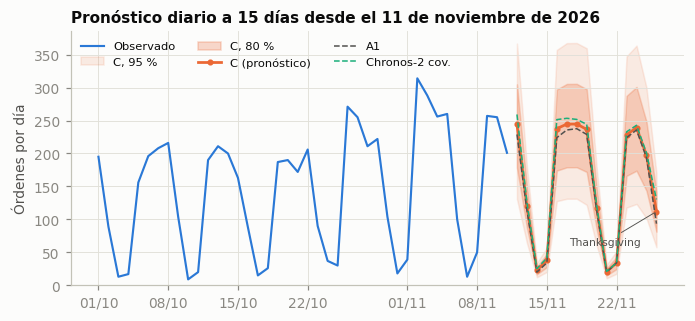

In [19]:
# Figura 11. Pronóstico diario del 12 al 26 de noviembre de 2026
fig, ax = plt.subplots(figsize=(7.2, 3.0))
hist = d["2026-10-01":]
ax.plot(hist.index, hist.ordenes, color=C["azul"], lw=1.4, label="Observado")
ax.fill_between(dias_f, fp["C-lo-95"], fp["C-hi-95"], color=C["naranja"], alpha=0.12, label="C, 95 %")
ax.fill_between(dias_f, fp["C-lo-80"], fp["C-hi-80"], color=C["naranja"], alpha=0.25, label="C, 80 %")
ax.plot(dias_f, fp.C, color=C["naranja"], lw=1.8, marker="o", ms=3, label="C (pronóstico)")
ax.plot(dias_f, fp.A1, color=C["tinta2"], lw=1, ls="--", label="A1")
ax.plot(dias_f, fp.Chronos2_cov, color=C["aqua"], lw=1, ls="--", label="Chronos-2 cov.")
ax.annotate("Thanksgiving", xy=(pd.Timestamp("2026-11-26"), fp.C.iloc[-1]), xytext=(-10, -22), textcoords="offset points",
            fontsize=7, color=C["tinta2"], ha="right", arrowprops=dict(arrowstyle="-", color=C["tinta2"], lw=0.6))
ax.set(ylabel="Órdenes por día", ylim=(0, None), title="Pronóstico diario a 15 días desde el 11 de noviembre de 2026")
ax.legend(loc="upper left", ncol=3, fontsize=7.5); ax.xaxis.set_major_formatter(FMT_DIA)
fig.savefig("figuras/fig11_pronostico_diario.png"); plt.show()

## 9. Conclusiones

1. **El método 2, Chronos-2 con covariables de feriado por país y de acero, es el mejor modelo individual** (MASE 0.701, gana al ingenuo semanal en 48 de 52 orígenes). Las covariables son las que lo hacen útil: sin ellas Chronos-2 queda en 0.791 (Wilcoxon p < 0.001) y en los días de feriado su error se dispara (1.381 contra 1.098).
2. **El método 1, el reparto del pronóstico mensual con perfil semanal y feriados por país (A1), queda cerca** (0.737; la diferencia con Chronos-2 no es significativa, p = 0.21) y es el mejor en los feriados (0.732). Repartir solo lo que falta del mes (A2, 0.971) empeora, porque el pronóstico mensual erró en 2026 y el descuento traslada todo el error a los días que quedan.
3. **La combinación C = (A1 + Chronos-2 cov.) / 2 es el pronóstico final** (MASE 0.680, error del total de 15 días 6.0 %). Supera a A1 en 34 de 52 orígenes (p = 0.006), no es distinta de Chronos-2 (p = 0.34) y reduce a la mitad el error de Chronos-2 en los feriados (0.865 contra 1.098).
4. **Contrastes:** LightGBM con rezagos y covariables (0.716) es competitivo; Prophet (0.763), TimesFM (0.774) y SARIMAX (0.777) quedan detrás de los dos métodos, y MSTL (0.902) y ETS (0.997) apenas superan al ingenuo semanal (1.131).
5. **Conocer el plan del acero mejora el pronóstico:** con la proporción diaria realizada en lugar de la persistencia de 14 días, Chronos-2 baja de 0.701 a 0.663 (gana en 36 de 52, p < 0.001). Si planificación comunica la apertura o el cierre del acero, conviene pasarlo como covariable.
6. **Intervalos:** el intervalo empírico de C (cocientes por bloque de horizonte) cubre el 77 % y el 93 % frente al 80 % y 95 % nominales, algo por debajo pero cerca. En los feriados la cobertura cae al 40 % y 60 %: en esas semanas conviene planificar con margen adicional.
7. **Pronóstico del 12 al 26 de noviembre de 2026 (C): 2,336 órdenes**, entre 117 y 245 por día hábil y 112 el día de Thanksgiving. Es 1.6 % menos que los mismos días de 2025 (2,373), principalmente porque el 26 de noviembre de 2026 es Thanksgiving y en 2025 cayó el 27, fuera del tramo.